In [2]:
import matplotlib as mpl
import matplotlib.pyplot as plt
import numpy as np
import os
from datetime import datetime
import pandas as pd

mpl.rcParams['figure.figsize'] = (10, 8)
mpl.rcParams['axes.grid'] = False

In [3]:
def parser(x):
  return datetime.strptime(x,'%m/%d/%Y')

In [4]:
df = pd.read_csv('https://raw.githubusercontent.com/srivatsan88/YouTubeLI/master/dataset/electricity_consumption.csv', parse_dates = ['Bill_Date'],date_parser=parser)

<ipython-input-4-a7d8465ae261>:1: FutureWarning: The argument 'date_parser' is deprecated and will be removed in a future version. Please use 'date_format' instead, or read your data in as 'object' dtype and then call 'to_datetime'.
  df = pd.read_csv('https://raw.githubusercontent.com/srivatsan88/YouTubeLI/master/dataset/electricity_consumption.csv', parse_dates = ['Bill_Date'],date_parser=parser)


In [5]:
df.head()

,Bill_Date,On_peak,Off_peak,Usage_charge,Billed_amount,Billing_days
0,2016-01-01,365,1423.5,219.0,247.73,31
1,2016-02-01,292,1138.8,175.2,234.11,31
2,2016-03-01,130,507.0,78.0,123.85,29
3,2016-04-01,117,456.3,70.2,111.22,29
4,2016-05-01,136,530.4,81.6,118.37,29


In [6]:
bill_df = df.set_index('Bill_Date')
bill_df.head()

,On_peak,Off_peak,Usage_charge,Billed_amount,Billing_days
Bill_Date,,,,,
2016-01-01,365,1423.5,219.0,247.73,31
2016-02-01,292,1138.8,175.2,234.11,31
2016-03-01,130,507.0,78.0,123.85,29
2016-04-01,117,456.3,70.2,111.22,29
2016-05-01,136,530.4,81.6,118.37,29


Displaying bill aumount from 2016 to 2018

In [9]:
bill_2018 = bill_df['2016':'2018'][['Billed_amount']]
bill_2018

,Billed_amount
Bill_Date,
2016-01-01,247.73
2016-02-01,234.11
2016-03-01,123.85
2016-04-01,111.22
2016-05-01,118.37
2016-06-01,77.81
2016-07-01,86.67
2016-08-01,122.40
2016-09-01,223.62


### Simple Moving Average

$\text{Moving average} = \dfrac{t + (t-1) +(t-2) + \cdots + (t-n)}{n} $

In [10]:
bill_2018['Billed_amount'].rolling(window=3).mean()

,Billed_amount
Bill_Date,
2016-01-01,NaN
2016-02-01,NaN
2016-03-01,201.896667
2016-04-01,156.393333
2016-05-01,117.813333
2016-06-01,102.466667
2016-07-01,94.283333
2016-08-01,95.626667
2016-09-01,144.230000


In [12]:
bill_2018['ma_rolling_3'] = bill_2018['Billed_amount'].rolling(window=3).mean()
bill_2018.head()

,Billed_amount,ma_rolling_3
Bill_Date,,
2016-01-01,247.73,NaN
2016-02-01,234.11,NaN
2016-03-01,123.85,201.896667
2016-04-01,111.22,156.393333
2016-05-01,118.37,117.813333


<Axes: xlabel='Bill_Date'>

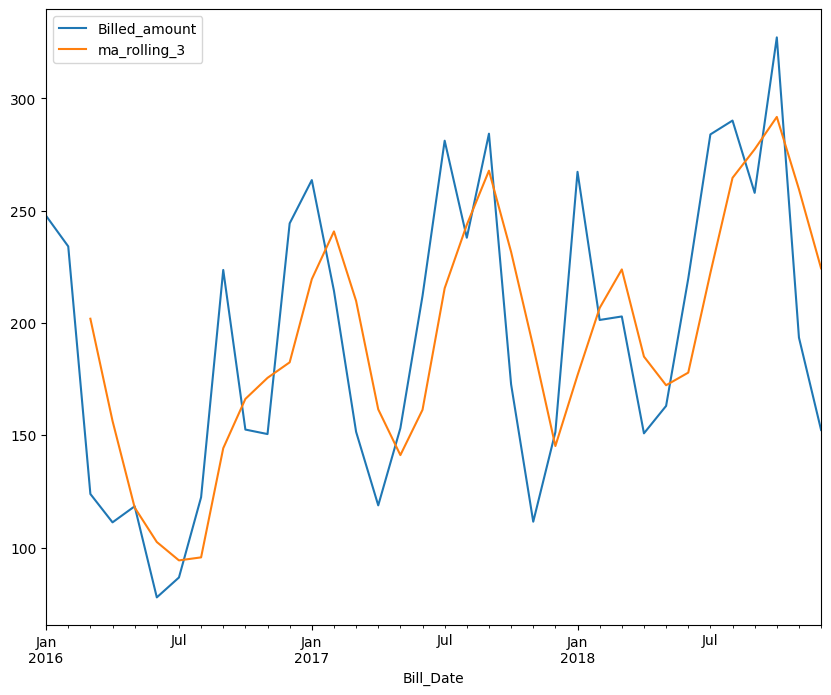

In [13]:
bill_2018.plot()

## 2. Weighted Moving Average

In [14]:
def wma(weights):
  def calc(x):
    return (weights*x).mean()
  return calc

In [16]:
bill_2018['Billed_amount'].rolling(window=3).apply(wma(np.array([0.5,1,1.5])))

,Billed_amount
Bill_Date,
2016-01-01,NaN
2016-02-01,NaN
2016-03-01,181.250000
2016-04-01,135.911667
2016-05-01,116.900000
2016-06-01,96.898333
2016-07-01,89.000000
2016-08-01,103.058333
2016-09-01,167.055000


In [18]:
bill_2018['WEighted_Moving_Average'] = bill_2018['Billed_amount'].rolling(window=3).apply(wma(np.array([0.5,1,1.5])))
bill_2018

,Billed_amount,ma_rolling_3,WEighted_Moving_Average
Bill_Date,,,
2016-01-01,247.73,NaN,NaN
2016-02-01,234.11,NaN,NaN
2016-03-01,123.85,201.896667,181.250000
2016-04-01,111.22,156.393333,135.911667
2016-05-01,118.37,117.813333,116.900000
2016-06-01,77.81,102.466667,96.898333
2016-07-01,86.67,94.283333,89.000000
2016-08-01,122.40,95.626667,103.058333
2016-09-01,223.62,144.230000,167.055000


<Axes: xlabel='Bill_Date'>

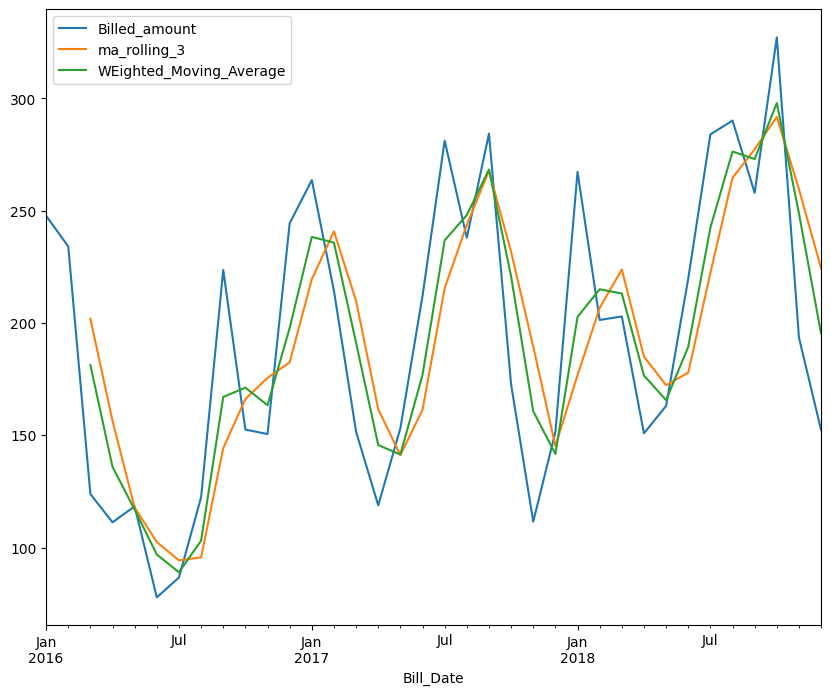

In [19]:
bill_2018.plot()

## 3. Exponential Moving Average

Exponential moving average = (Close - previous EMA*(2(span+1)) + previous EMA

In [22]:
bill_2018['Billed_amount'].ewm(span=3,adjust = False,min_periods = 3).mean()



,Billed_amount
Bill_Date,
2016-01-01,NaN
2016-02-01,NaN
2016-03-01,182.385000
2016-04-01,146.802500
2016-05-01,132.586250
2016-06-01,105.198125
2016-07-01,95.934063
2016-08-01,109.167031
2016-09-01,166.393516


In [23]:
bill_2018['EWM_Window_3'] = bill_2018['Billed_amount'].ewm(span=3,adjust = False,min_periods =3).mean()

<Axes: xlabel='Bill_Date'>

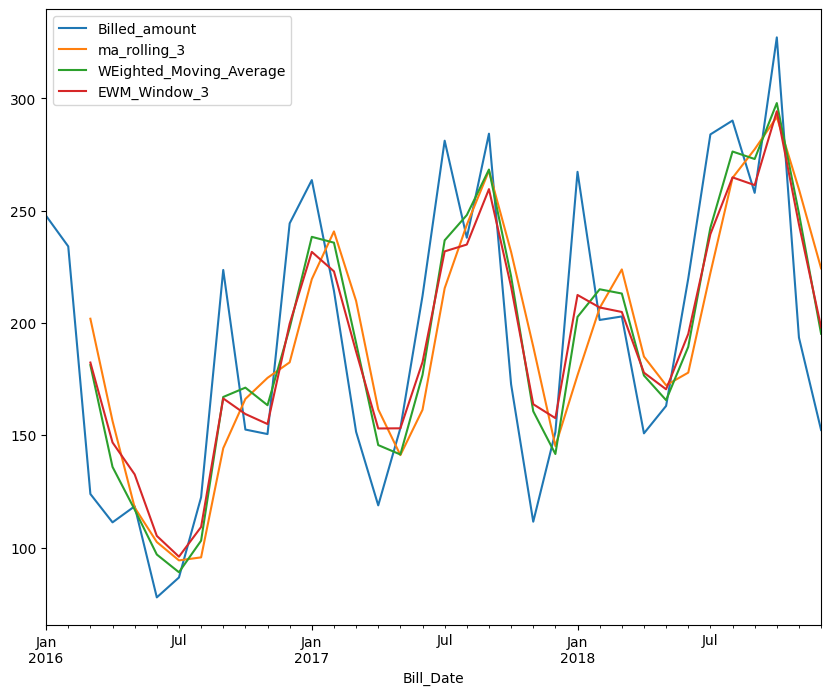

In [24]:
bill_2018.plot()

## 4. Exponential Smoothing

$\hat{Y}_{t+1} = \alpha \left[Y_{t} + (1-\alpha)Y_{t-1} + (1-\alpha)^{2}Y_{t-2}+(1-\alpha)^{3}Y_{t-3} + \cdots\right]$

In [25]:
bill_2018['Billed_amount'].ewm(alpha=0.7,adjust = False,min_periods =3).mean()

,Billed_amount
Bill_Date,
2016-01-01,NaN
2016-02-01,NaN
2016-03-01,158.153800
2016-04-01,125.300140
2016-05-01,120.449042
2016-06-01,90.601713
2016-07-01,87.849514
2016-08-01,112.034854
2016-09-01,190.144456


In [27]:
bill_2018['ewm_3_7']= bill_2018['Billed_amount'].ewm(alpha= 0.7,adjust = False,min_periods = 3).mean()

In [28]:
bill_2018

,Billed_amount,ma_rolling_3,WEighted_Moving_Average,EWM_Window_3,ewm_3_7
Bill_Date,,,,,
2016-01-01,247.73,NaN,NaN,NaN,NaN
2016-02-01,234.11,NaN,NaN,NaN,NaN
2016-03-01,123.85,201.896667,181.250000,182.385000,158.153800
2016-04-01,111.22,156.393333,135.911667,146.802500,125.300140
2016-05-01,118.37,117.813333,116.900000,132.586250,120.449042
2016-06-01,77.81,102.466667,96.898333,105.198125,90.601713
2016-07-01,86.67,94.283333,89.000000,95.934063,87.849514
2016-08-01,122.40,95.626667,103.058333,109.167031,112.034854
2016-09-01,223.62,144.230000,167.055000,166.393516,190.144456


<Axes: xlabel='Bill_Date'>

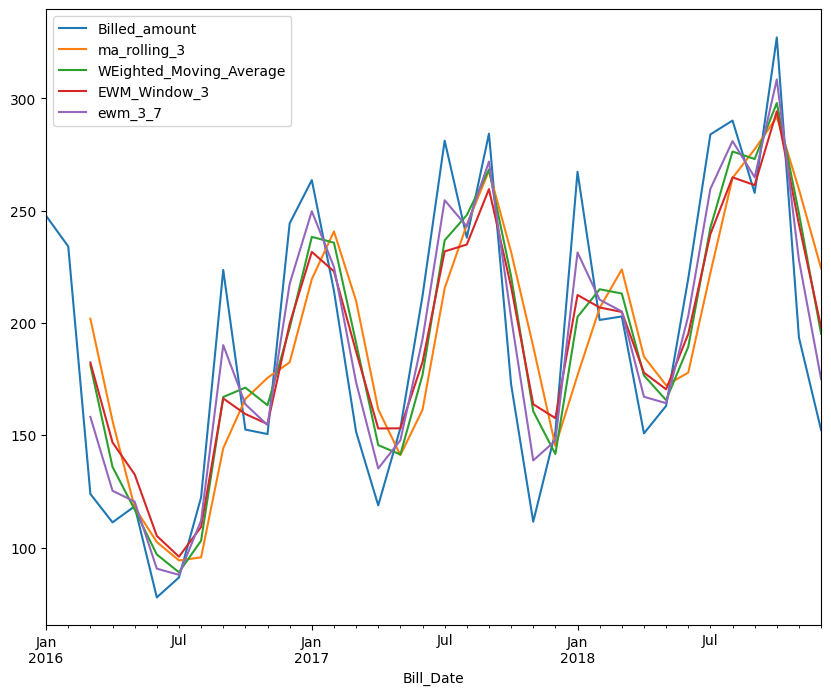

In [29]:
bill_2018.plot()

What happens if we change alpha to 0.3

In [37]:
bill_2018['ewm_3_3'] = bill_2018['Billed_amount'].ewm(alpha =0.3,adjust = False,min_periods = 3).mean().shift(1)

In [33]:
bill_2018.columns

Index(['Billed_amount', 'ma_rolling_3', 'WEighted_Moving_Average',
       'EWM_Window_3', 'ewm_3_7', 'ewm_3_3'],
      dtype='object')

<Axes: xlabel='Bill_Date'>

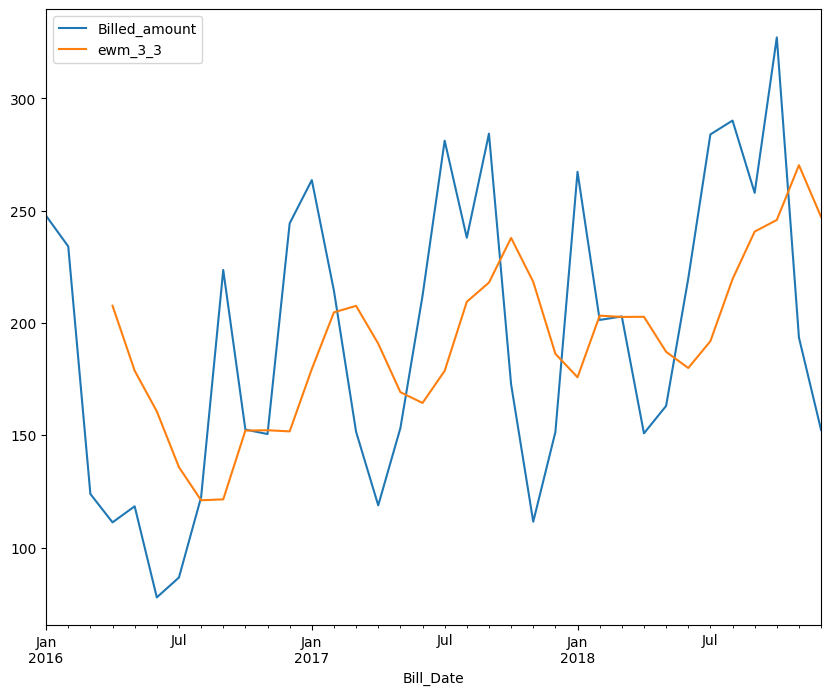

In [38]:
bill_2018[['Billed_amount','ewm_3_3']].plot()

### Model Evaluation

$\text{RMSE} = \sqrt{\sum_{i=1}^{n}\frac{(\hat{y_{i} - y_{i})^{2}}{n}}{2}$



In [40]:
bill_2018.columns

Index(['Billed_amount', 'ma_rolling_3', 'WEighted_Moving_Average',
       'EWM_Window_3', 'ewm_3_7', 'ewm_3_3'],
      dtype='object')

In [48]:
bill_2018.iloc[1:].columns

Index(['Billed_amount', 'ma_rolling_3', 'WEighted_Moving_Average',
       'EWM_Window_3', 'ewm_3_7', 'ewm_3_3'],
      dtype='object')

In [51]:
list = np.array(bill_2018.columns)

In [52]:
list

array(['Billed_amount', 'ma_rolling_3', 'WEighted_Moving_Average',
       'EWM_Window_3', 'ewm_3_7', 'ewm_3_3'], dtype=object)

In [54]:
list.delete('Billed_amount')

AttributeError: 'numpy.ndarray' object has no attribute 'delete'

In [55]:
import numpy as np # Assuming you have already imported numpy

# Assuming bill_2018 is your DataFrame and you want to remove 'Billed_amount' from the columns

# Get the column names as a list
my_list = bill_2018.columns.tolist()

# Find the index of 'Billed_amount'
index_to_remove = my_list.index('Billed_amount')

# Use np.delete to remove the element at the specified index
updated_columns = np.delete(my_list, index_to_remove)

# You can now use this updated_columns array as needed
print(updated_columns)

['ma_rolling_3' 'WEighted_Moving_Average' 'EWM_Window_3' 'ewm_3_7'
 'ewm_3_3']


In [64]:
for i in range(len(updated_columns)):
  print(f'{updated_columns[i]} has a root mean squared error of : {(((bill_2018["Billed_amount"]-bill_2018[updated_columns[i]]))**2).mean()**0.5}')
  #i = i+1 #The loop variable is automatically incremented, so this line is unnecessary

ma_rolling_3 has a root mean squared error of : 46.20467489716751
WEighted_Moving_Average has a root mean squared error of : 32.721421843607594
EWM_Window_3 has a root mean squared error of : 32.60927202405608
ewm_3_7 has a root mean squared error of : 19.038672729082858
ewm_3_3 has a root mean squared error of : 65.22424423118377


In [65]:
for i in range(len(updated_columns)):
  print(f'{updated_columns[i]} has a root mean squared error of : {np.sqrt(((bill_2018["Billed_amount"] - bill_2018[updated_columns[i]])**2).mean())}')

ma_rolling_3 has a root mean squared error of : 46.20467489716751
WEighted_Moving_Average has a root mean squared error of : 32.721421843607594
EWM_Window_3 has a root mean squared error of : 32.60927202405608
ewm_3_7 has a root mean squared error of : 19.038672729082858
ewm_3_3 has a root mean squared error of : 65.22424423118377
